In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Definimos la ruta del archivo crudo (Bronze)

ruta_bronze = "../data/bronze/nasa_cali_raw.csv"

# 2. Detectamos en qué línea terminan los metadatos de la API de NASA
lineas_saltar = 0
with open(ruta_bronze, 'r', encoding='utf-8') as f:
    for linea in f:
        lineas_saltar += 1
        if "-END HEADER-" in linea:
            break

print(f"Se saltaron {lineas_saltar} líneas de texto introductorio de la NASA.")

# 3. Cargar el dataframe
df = pd.read_csv(ruta_bronze, skiprows=lineas_saltar)
display(df.head())

Se saltaron 11 líneas de texto introductorio de la NASA.


,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,PRECTOTCORR
0,2021,1,1,3.8227,15.65,1.18
1,2021,1,2,3.6401,15.99,3.23
2,2021,1,3,3.5314,15.93,10.45
3,2021,1,4,4.2283,15.66,9.70
4,2021,1,5,3.1757,15.36,5.35


In [ ]:
#Cali - Deimesiones del dataset y tipos de datos

print("--- DIMENSIONES DEL DATASET ---")
print(f"Número total de filas: {df.shape[0]}")
print(f"Número total de columnas: {df.shape[1]}\n")

print("--- TIPOS DE DATOS ---")
df.info()

--- DIMENSIONES DEL DATASET ---
Número total de filas: 1461
Número total de columnas: 6

--- TIPOS DE DATOS ---
<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   YEAR               1461 non-null   int64  
 1   MO                 1461 non-null   int64  
 2   DY                 1461 non-null   int64  
 3   ALLSKY_SFC_SW_DWN  1461 non-null   float64
 4   T2M                1461 non-null   float64
 5   PRECTOTCORR        1461 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 68.6 KB


In [ ]:
#Cali - Valores nulos por columna y filas duplicadas

print("--- VALORES NULOS POR COLUMNA ---")

# Sumamos la cantidad de celdas vacías por cada columna
print(df.isnull().sum())

print("\n--- FILAS DUPLICADAS ---")

# Buscamos si hay filas exactamente iguales
duplicados = df.duplicated().sum()
print(f"Total de registros repetidos: {duplicados}")

--- VALORES NULOS POR COLUMNA ---
YEAR                 0
MO                   0
DY                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
PRECTOTCORR          0
dtype: int64

--- FILAS DUPLICADAS ---
Total de registros repetidos: 0


In [ ]:
#importamos librerías necesarias nuevamente para el análisis de las otras ciudades (Bogota, Barranquilla y Medellin)
import pandas as pd

# Lista de las ciudades faltantes
ciudades = ["bogota", "barranquilla", "medellin"]
resultados = []

for ciudad in ciudades:
    # Definimos la ruta del archivo crudo (Bronze)
    ruta_bronze = f"../data/bronze/nasa_{ciudad}_raw.csv"
    
    # Detectamos el fin de los metadatos
    with open(ruta_bronze, "r", encoding="utf-8") as f:
        lineas = f.readlines()
        
    fila_inicio = 0
    for i, linea in enumerate(lineas):
        if "-END HEADER-" in linea:
            fila_inicio = i + 1
            break
            
    # Cargarmos el dataframe
    df_ciudad = pd.read_csv(ruta_bronze, skiprows=fila_inicio)
    
    # Extraemos la información masimportante "clave" y la guardamos como  diccionario
    info_ciudad = {
        "Ciudad": ciudad.upper(),
        "Filas": df_ciudad.shape[0],
        "Columnas": df_ciudad.shape[1],
        "Nulos (Radiación)": df_ciudad['ALLSKY_SFC_SW_DWN'].isnull().sum(),
        "Nulos (Temperatura)": df_ciudad['T2M'].isnull().sum(),
        "Nulos (Lluvia)": df_ciudad['PRECTOTCORR'].isnull().sum(),
        "Filas Duplicadas": df_ciudad.duplicated().sum()
    }
    
    resultados.append(info_ciudad)

# Convertimos los resultados en una tabla para que no ver los datos completos sin recorte
df_resumen = pd.DataFrame(resultados)
display(df_resumen)

,Ciudad,Filas,Columnas,Nulos (Radiación),Nulos (Temperatura),Nulos (Lluvia),Filas Duplicadas
0,BOGOTA,1461,6,0,0,0,0
1,BARRANQUILLA,1461,6,0,0,0,0
2,MEDELLIN,1461,6,0,0,0,0


In [4]:
print("--- ESTADÍSTICAS DESCRIPTIVAS ---")

# Filtramos solo las columnas climáticas relevantes para el proyecto
variables_clima = ['ALLSKY_SFC_SW_DWN', 'T2M', 'PRECTOTCORR']
display(df[variables_clima].describe())

--- ESTADÍSTICAS DESCRIPTIVAS ---


,ALLSKY_SFC_SW_DWN,T2M,PRECTOTCORR
count,1461.000000,1461.000000,1461.000000
mean,4.177158,16.482977,3.562909
std,0.671680,0.879883,4.880873
min,1.135400,13.810000,0.000000
25%,3.784100,15.880000,0.310000
50%,4.175300,16.420000,1.650000
75%,4.623600,17.000000,4.840000
max,6.140900,19.360000,29.890000


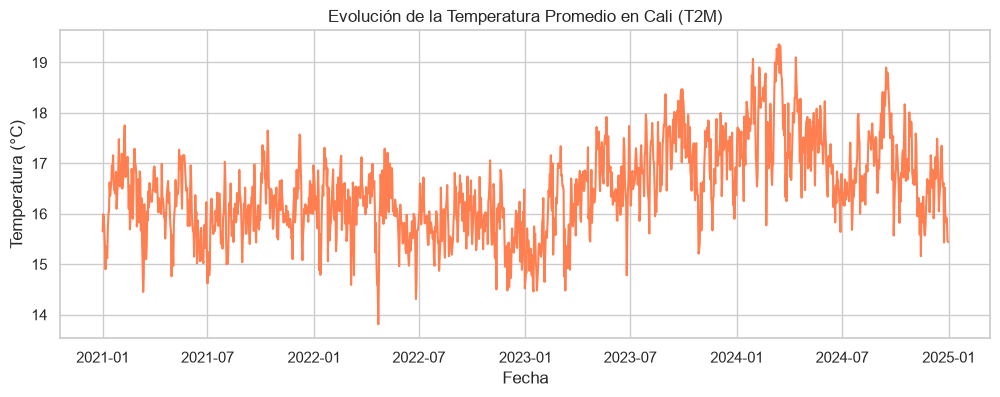

In [5]:
# Unimos las columnas YEAR, MO y DY en una columna formato fecha
df['fecha'] = pd.to_datetime(df[['YEAR', 'MO', 'DY']].rename(columns={'YEAR': 'year', 'MO': 'month', 'DY': 'day'}))

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 4))

# Graficamos la temperatura promedio (T2M)
sns.lineplot(data=df, x='fecha', y='T2M', color='coral')
plt.title("Evolución de la Temperatura Promedio en Cali (T2M)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.show()

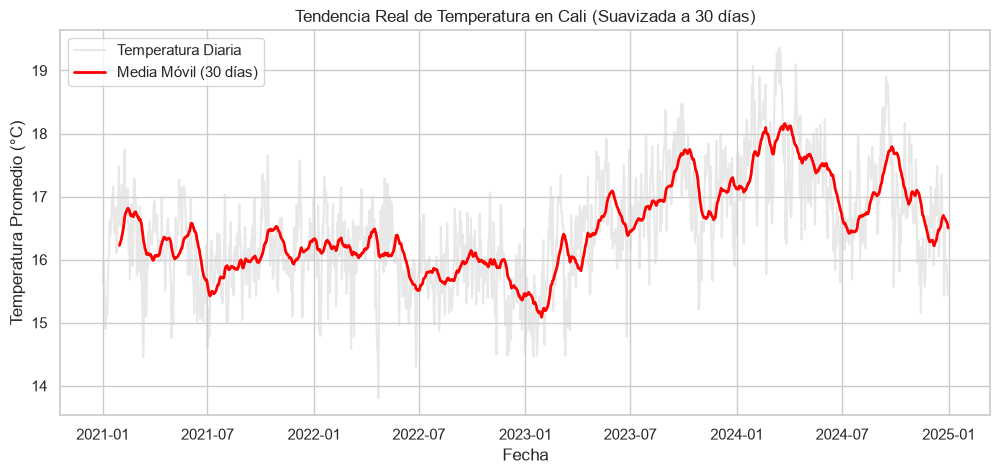

In [14]:
#Tendencias suavizadas 

# Calcular el promedio rodante de los últimos 30 días
df['temp_media_movil_30'] = df['T2M'].rolling(window=30).mean()

plt.figure(figsize=(12, 5))
# Gráfica de fondo con los datos diarios originales
sns.lineplot(data=df, x='fecha', y='T2M', color='lightgrey', label='Temperatura Diaria', alpha=0.5)
# Gráfica principal con la tendencia suavizada
sns.lineplot(data=df, x='fecha', y='temp_media_movil_30', color='red', label='Media Móvil (30 días)', linewidth=2)

plt.title("Tendencia Real de Temperatura en Cali (Suavizada a 30 días)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura Promedio (°C)")
plt.legend()
plt.show()

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_7848\2355722196.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='MO', y='T2M', palette='coolwarm')


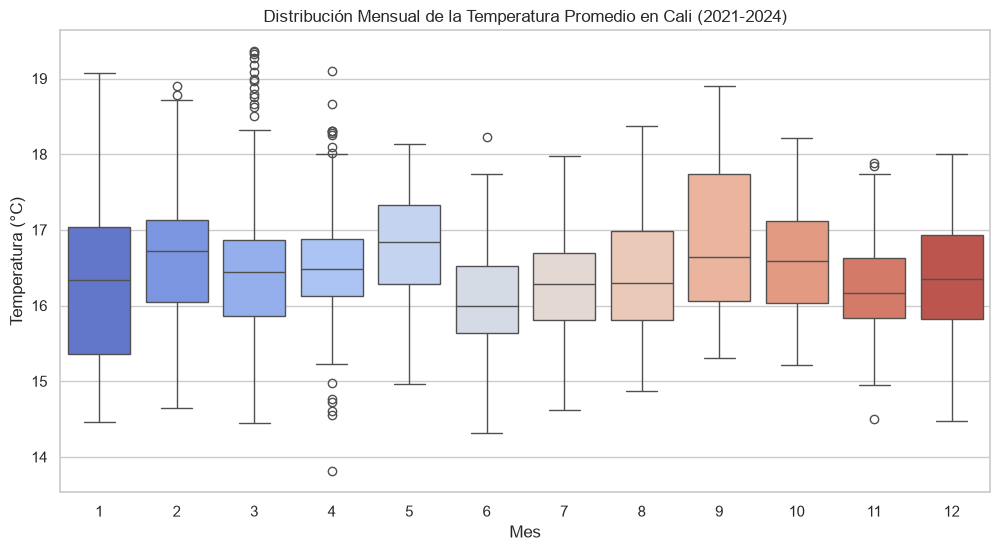

In [6]:
#Distribución mensual de la temperatura, gráfico de cajas muestra cómo varía la temperatura de Cali mes a mes

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='MO', y='T2M', palette='coolwarm')
plt.title("Distribución Mensual de la Temperatura Promedio en Cali (2021-2024)")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.show()

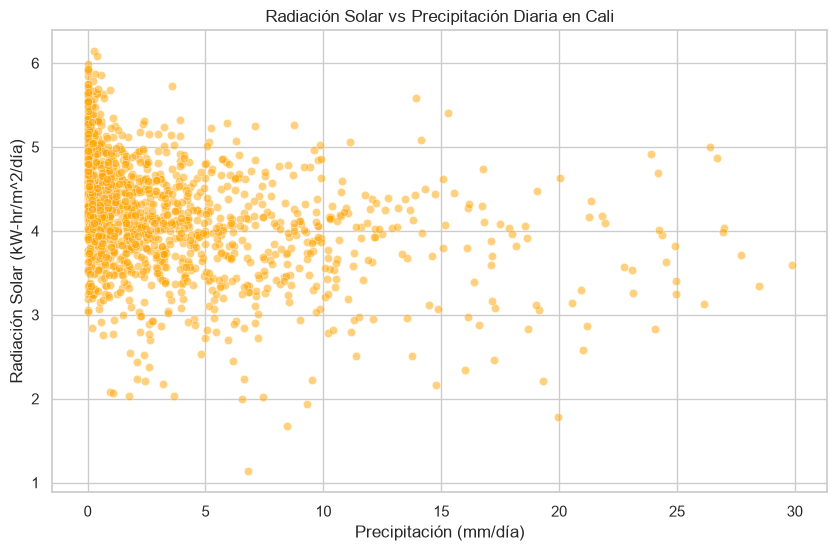

In [ ]:
#Cali - Relación entre Radiación Solar y Precipitación       

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='PRECTOTCORR', y='ALLSKY_SFC_SW_DWN', alpha=0.5, color='orange')
plt.title("Radiación Solar vs Precipitación Diaria en Cali")
plt.xlabel("Precipitación (mm/día)")
plt.ylabel("Radiación Solar (kW-hr/m^2/día)")
plt.show()

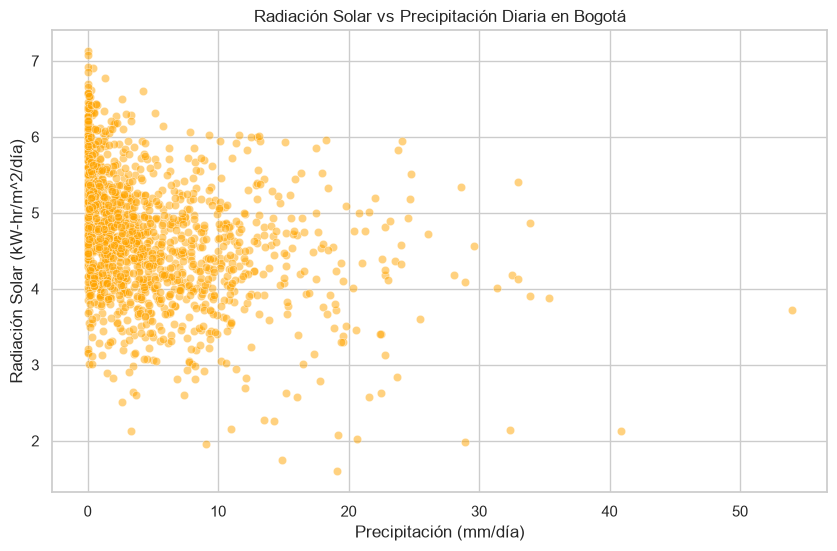

In [ ]:
#Bogota - Relación entre Radiación Solar y Precipitación  

# Cargamos los datos Silver y filtramos por la ciudad de  Bogotá
df_silver = pd.read_csv("../data/silver/nasa_clean.csv")
df_bogota = df_silver[df_silver['ciudad'] == 'BOGOTA']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_bogota, x='precipitacion', y='radiacion_solar', alpha=0.5, color='orange')
plt.title("Radiación Solar vs Precipitación Diaria en Bogotá")
plt.xlabel("Precipitación (mm/día)")
plt.ylabel("Radiación Solar (kW-hr/m^2/día)")
plt.show()

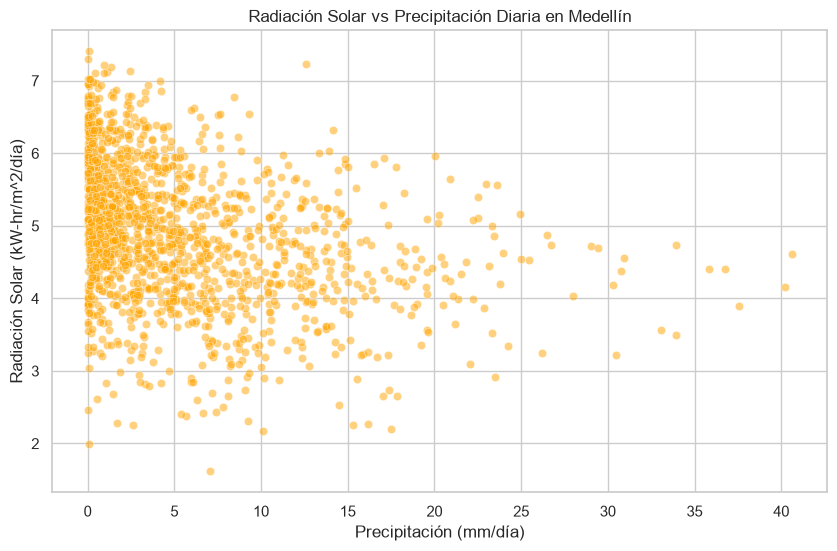

In [30]:
#Medellin - Relación entre Radiación Solar y Precipitación 

# Cargamos los datos Silver y filtramos por la ciudad de Medellín
df_silver = pd.read_csv("../data/silver/nasa_clean.csv")
df_medellin = df_silver[df_silver['ciudad'] == 'MEDELLIN']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_medellin, x='precipitacion', y='radiacion_solar', alpha=0.5, color='orange')
plt.title("Radiación Solar vs Precipitación Diaria en Medellín")
plt.xlabel("Precipitación (mm/día)")
plt.ylabel("Radiación Solar (kW-hr/m^2/día)")
plt.show()

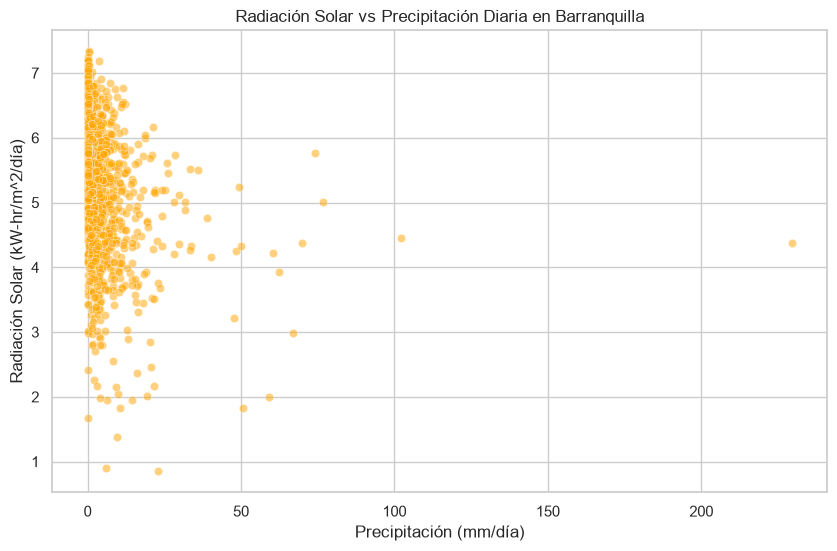

In [33]:
#Barranquilla - Relación entre Radiación Solar y Precipitación 

# Cargamos los datos Silver y filtramos por la ciudad de   Barranquilla

df_silver = pd.read_csv("../data/silver/nasa_clean.csv")
df_barranquilla = df_silver[df_silver['ciudad'] == 'BARRANQUILLA']

# Cargar datos Silver y filtrar por Barranquilla
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_barranquilla, x='precipitacion', y='radiacion_solar', alpha=0.5, color='orange')
plt.title("Radiación Solar vs Precipitación Diaria en Barranquilla")
plt.xlabel("Precipitación (mm/día)")
plt.ylabel("Radiación Solar (kW-hr/m^2/día)")
plt.show()

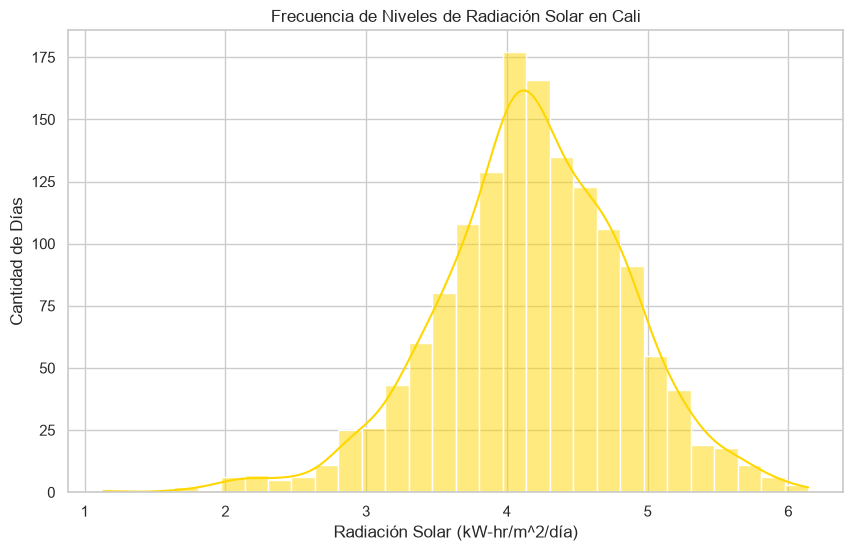

In [8]:
#Frecuencia de Radiación Solar (Histograma)

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='ALLSKY_SFC_SW_DWN', bins=30, kde=True, color='gold')
plt.title("Frecuencia de Niveles de Radiación Solar en Cali")
plt.xlabel("Radiación Solar (kW-hr/m^2/día)")
plt.ylabel("Cantidad de Días")
plt.show()

In [10]:
#Verificación visual de valores nulos ocultos (-999)

anomalias = df[(df['T2M'] == -999) | (df['ALLSKY_SFC_SW_DWN'] == -999) | (df['PRECTOTCORR'] == -999)]
print(f"Total de registros con valor -999 (faltantes de la NASA): {len(anomalias)}")

if len(anomalias) > 0:
    display(anomalias.head())
else:
    print("El dataset no contiene valores -999. Los datos están completamente íntegros.")

Total de registros con valor -999 (faltantes de la NASA): 0
El dataset no contiene valores -999. Los datos están completamente íntegros.


In [11]:
# Se crea un rango de fechas ideal desde el primer al último día registrado
rango_ideal = pd.date_range(start=df['fecha'].min(), end=df['fecha'].max())
fechas_faltantes = rango_ideal.difference(df['fecha'])

print(f"Total de días esperados: {len(rango_ideal)}")
print(f"Total de días registrados: {len(df)}")
print(f"Días faltantes: {len(fechas_faltantes)}")

if len(fechas_faltantes) > 0:
    print("Fechas que faltan en el dataset:", fechas_faltantes)
else:
    print("El dataset es temporalmente continuo. No faltan días.")

Total de días esperados: 1461
Total de días registrados: 1461
Días faltantes: 0
El dataset es temporalmente continuo. No faltan días.


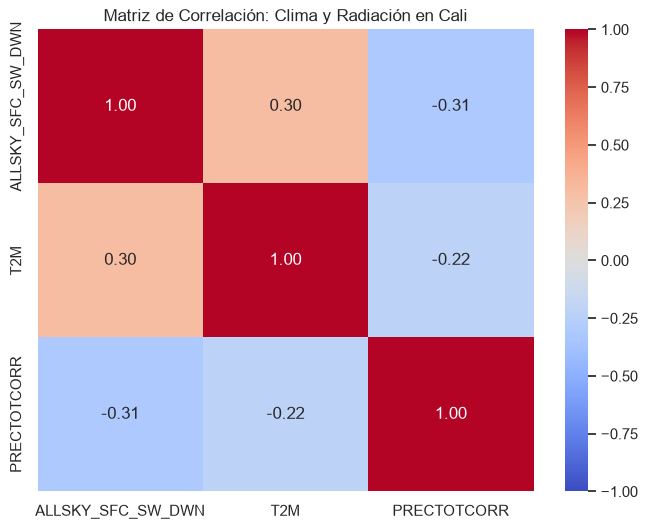

In [12]:
#Matriz de Correlación

plt.figure(figsize=(8, 6))
# Seleccionamos solo las variables climáticas numéricas
variables_corr = df[['ALLSKY_SFC_SW_DWN', 'T2M', 'PRECTOTCORR']]
matriz_correlacion = variables_corr.corr()

# Graficar el mapa de calor
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de Correlación: Clima y Radiación en Cali")
plt.show()

In [13]:
#Identificación de Extremos

print("--- TOP 5 DÍAS MÁS CALUROSOS ---")
display(df[['fecha', 'T2M', 'PRECTOTCORR']].sort_values(by='T2M', ascending=False).head())

print("\n--- TOP 5 DÍAS CON MAYOR POTENCIAL SOLAR ---")
display(df[['fecha', 'ALLSKY_SFC_SW_DWN', 'T2M']].sort_values(by='ALLSKY_SFC_SW_DWN', ascending=False).head())

--- TOP 5 DÍAS MÁS CALUROSOS ---


,fecha,T2M,PRECTOTCORR
1168,2024-03-14,19.36,0.21
1167,2024-03-13,19.35,0.88
1170,2024-03-16,19.33,0.06
1164,2024-03-10,19.27,0.18
1165,2024-03-11,19.18,0.96



--- TOP 5 DÍAS CON MAYOR POTENCIAL SOLAR ---


,fecha,ALLSKY_SFC_SW_DWN,T2M
268,2021-09-26,6.1409,16.12
1148,2024-02-23,6.0854,17.82
1325,2024-08-18,5.9916,17.51
1337,2024-08-30,5.9338,16.85
899,2023-06-19,5.9141,16.86


In [22]:
#Cargamos de nuevo el dataset de las 4 ciudades

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


ruta_silver = "../data/silver/nasa_clean.csv"
df_silver = pd.read_csv(ruta_silver)

# Aca verificamos que las 4 ciudades estén en el dataset
print("Ciudades listas para analizar:", df_silver['ciudad'].unique())

Ciudades listas para analizar: <StringArray>
['CALI', 'BOGOTA', 'BARRANQUILLA', 'MEDELLIN']
Length: 4, dtype: str


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_7848\297439605.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=potencial_solar, x='ciudad', y='radiacion_solar', palette='YlOrBr_r')


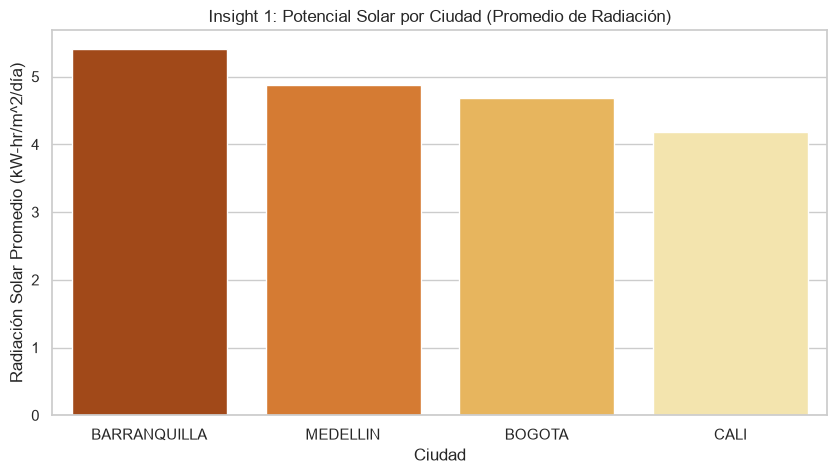

,ciudad,radiacion_solar
0,BARRANQUILLA,5.413805
1,MEDELLIN,4.876755
2,BOGOTA,4.682941
3,CALI,4.177158


In [23]:
#¿Cuál ciudad tiene el mayor Potencial Solar?

plt.figure(figsize=(10, 5))
potencial_solar = df_silver.groupby('ciudad')['radiacion_solar'].mean().sort_values(ascending=False).reset_index()

sns.barplot(data=potencial_solar, x='ciudad', y='radiacion_solar', palette='YlOrBr_r')
plt.title("Insight 1: Potencial Solar por Ciudad (Promedio de Radiación)")
plt.xlabel("Ciudad")
plt.ylabel("Radiación Solar Promedio (kW-hr/m^2/día)")
plt.show()

# Mostrar la tabla con los valores exactos
display(potencial_solar)

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_7848\4127879195.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_silver, x='ciudad', y='temperatura', palette='coolwarm')


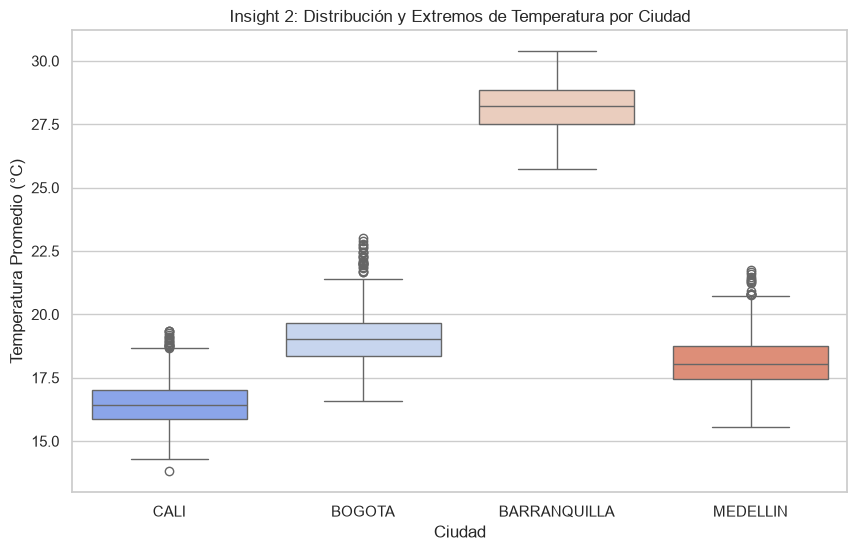

In [24]:
#Estabilidad Térmica (Extremos de calor y frío)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_silver, x='ciudad', y='temperatura', palette='coolwarm')
plt.title("Insight 2: Distribución y Extremos de Temperatura por Ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Temperatura Promedio (°C)")
plt.show()

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_7848\253535422.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lluvia_ciudad, x='ciudad', y='precipitacion', palette='Blues_r')


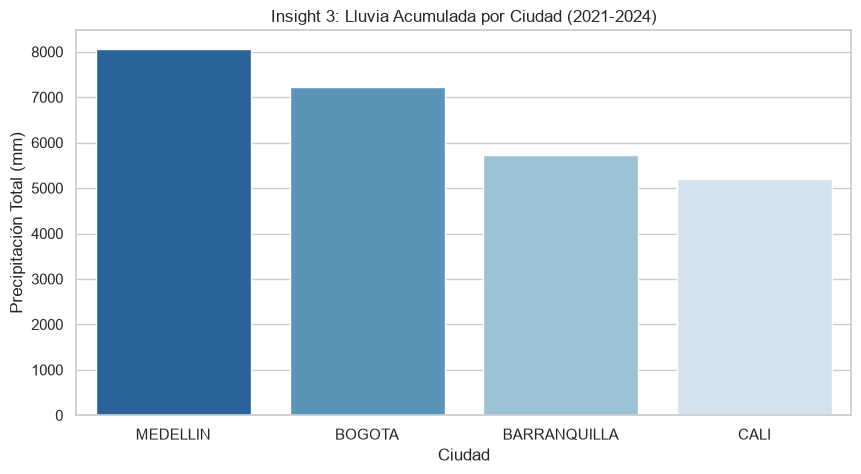

,ciudad,precipitacion
0,MEDELLIN,8069.00
1,BOGOTA,7223.88
2,BARRANQUILLA,5735.70
3,CALI,5205.41


In [25]:
#El factor Nubosidad (Lluvia Acumulada)

plt.figure(figsize=(10, 5))
# Sumamos la lluvia total por ciudad
lluvia_ciudad = df_silver.groupby('ciudad')['precipitacion'].sum().sort_values(ascending=False).reset_index()

sns.barplot(data=lluvia_ciudad, x='ciudad', y='precipitacion', palette='Blues_r')
plt.title("Insight 3: Lluvia Acumulada por Ciudad (2021-2024)")
plt.xlabel("Ciudad")
plt.ylabel("Precipitación Total (mm)")
plt.show()

# Mostrar la tabla
display(lluvia_ciudad)